# Feature Dependence and Model Structure

Seven selected synthetic classification cases compare feature laws, additive versus interaction targets, label dependence and fitting/tuning allocation. Every full-size case has 55 columns (54 varying and one constant) and 12,000 fitting / 4,000 tuning / 4,000 test rows.

The feature and target synthesis rules are specified in [README.md](README.md); observed results and interpretation limits are in [ANALYSIS.md](ANALYSIS.md). Core cases use 14 models at seed 42. The two structured prefix cases use six models at seeds 73, 74 and 75; attention is not evaluated in those two cases.

This notebook runs the selected suite by default. `RERUN = False` loads its checked results instead. `SMOKE = True` retains the selected case/model catalog but uses tiny data and two epochs; smoke results are not evidence for the analysis. Full CPU execution can take substantial time. Use a notebook kernel with the dependencies in `requirements.txt`; keep this notebook with its companion modules.

In [2]:
from pathlib import Path
import importlib
import json
import sys

candidates = (Path.cwd(), Path.cwd() / "feature_dependence_model_structure_study")
study_root = next((path.resolve() for path in candidates
                   if (path / "study.py").is_file() and (path / "datasets.py").is_file()), None)
if study_root is None:
    raise FileNotFoundError("Open this notebook from the study directory or its repository root.")
sys.path.insert(0, str(study_root))
for name in ("config", "datasets", "models", "redundancy", "training_process", "study", "presentation"):
    loaded = sys.modules.get(name)
    if loaded is not None and Path(getattr(loaded, "__file__", "")).resolve() != study_root / f"{name}.py":
        raise RuntimeError(f"Restart the kernel to clear a conflicting module: {name}")
importlib.invalidate_caches()

import numpy as np
import torch
import matplotlib.pyplot as plt
from IPython.display import Markdown, display
from config import selected_cases, case_models, case_seeds
from study import run_study, export_results
from presentation import comparison_markdown, plot_features, plot_comparison, plot_history

torch.set_num_threads(1)
print({"python": sys.version.split()[0], "numpy": np.__version__, "torch": str(torch.__version__)})

{'python': '3.13.16', 'numpy': '2.1.3', 'torch': '2.11.0+cpu'}


In [3]:
RERUN = True
SMOKE = False
DEVICE = "cpu"
CASE_NAMES = tuple(selected_cases())
CHECKED_RESULTS = study_root / "results" / "selected" / "20261024T025852680255Z" / "results.json"

catalog = selected_cases()
for name in CASE_NAMES:
    config = catalog[name]
    print(name, {"columns": config.n_features,
                 "rows": (config.train_rows, config.validation_rows, config.test_rows),
                 "target": config.scenario,
                 "allocation": config.allocation_policy,
                 "label_persistence": getattr(config, "label_persistence", 0),
                 "seeds": case_seeds(name), "models": case_models(name)})
print("Execution:", "rerun" if RERUN else "checked export", "| smoke:", SMOKE)

gaussian_additive {'columns': 55, 'rows': (12000, 4000, 4000), 'target': 'additive', 'allocation': 'random', 'label_persistence': 0, 'seeds': (42,), 'models': ('additive', 'learned_gate', 'corr_gate', 'recon_gate', 'redundancy_gate', 'shuffled_gate', 'fixed_redundancy_gate', 'additive_residual', 'redundancy_residual', 'low_rank', 'mlp', 'attention', 'shuffled_recon_gate', 'fixed_recon_gate')}
gaussian_interaction {'columns': 55, 'rows': (12000, 4000, 4000), 'target': 'interaction', 'allocation': 'random', 'label_persistence': 0, 'seeds': (42,), 'models': ('additive', 'learned_gate', 'corr_gate', 'recon_gate', 'redundancy_gate', 'shuffled_gate', 'fixed_redundancy_gate', 'additive_residual', 'redundancy_residual', 'low_rank', 'mlp', 'attention', 'shuffled_recon_gate', 'fixed_recon_gate')}
structured_additive {'columns': 55, 'rows': (12000, 4000, 4000), 'target': 'additive', 'allocation': 'random', 'label_persistence': 0.92, 'seeds': (42,), 'models': ('additive', 'learned_gate', 'corr_gat

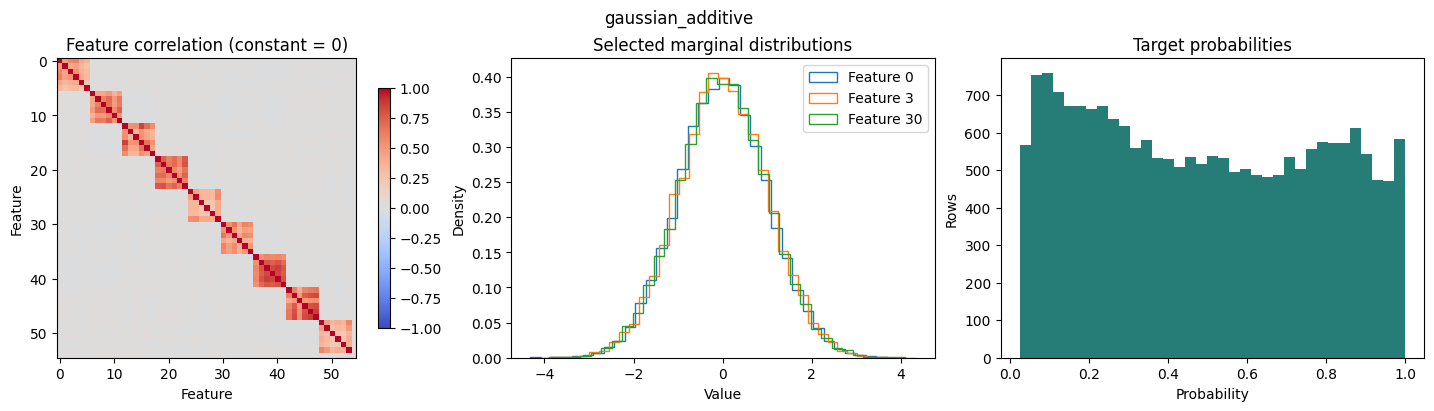

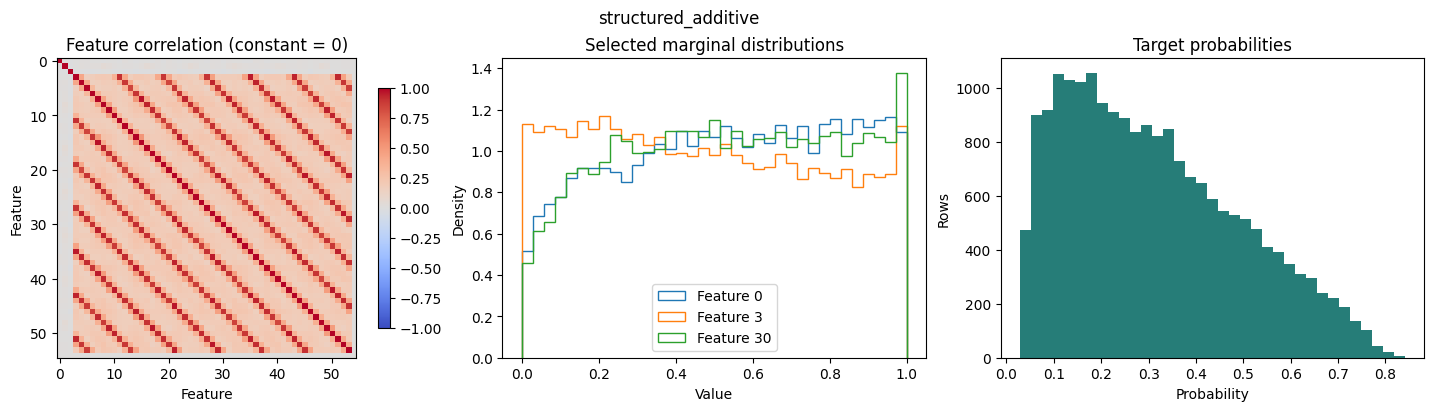

In [4]:
for name in ("gaussian_additive", "structured_additive"):
    figure = plot_features(catalog[name])
    figure.suptitle(name)
    plt.show()

In [5]:
if RERUN:
    bundle = run_study(CASE_NAMES, smoke=SMOKE, device=DEVICE, progress=True)
else:
    if SMOKE:
        raise ValueError("Set SMOKE = False when loading the checked full-size export.")
    bundle = json.loads(CHECKED_RESULTS.read_text(encoding="utf-8"))
    if tuple(bundle["cases"]) != CASE_NAMES:
        raise ValueError("The checked export must contain exactly the selected case catalog.")
print("Protocol:", bundle["protocol"], "| fitted rows:", len(bundle["summary"]))


Case: gaussian_additive
seed=42 | additive
seed=42 | learned_gate
seed=42 | corr_gate
seed=42 | recon_gate
seed=42 | redundancy_gate
seed=42 | shuffled_gate
seed=42 | fixed_redundancy_gate
seed=42 | additive_residual
seed=42 | redundancy_residual
seed=42 | low_rank
seed=42 | mlp
seed=42 | attention
seed=42 | shuffled_recon_gate
seed=42 | fixed_recon_gate

Case: gaussian_interaction
seed=42 | additive
seed=42 | learned_gate
seed=42 | corr_gate
seed=42 | recon_gate
seed=42 | redundancy_gate
seed=42 | shuffled_gate
seed=42 | fixed_redundancy_gate
seed=42 | additive_residual
seed=42 | redundancy_residual
seed=42 | low_rank
seed=42 | mlp
seed=42 | attention
seed=42 | shuffled_recon_gate
seed=42 | fixed_recon_gate

Case: structured_additive
seed=42 | additive
seed=42 | learned_gate
seed=42 | corr_gate
seed=42 | recon_gate
seed=42 | redundancy_gate
seed=42 | shuffled_gate
seed=42 | fixed_redundancy_gate
seed=42 | additive_residual
seed=42 | redundancy_residual
seed=42 | low_rank
seed=42 | ml

| Model | gaussian_additive | gaussian_interaction | structured_additive | structured_mixed | structured_interaction | structured_independent_prefix | structured_persistent_prefix |
| --- | ---: | ---: | ---: | ---: | ---: | ---: | ---: |
| additive | 0.513530 | 0.695205 | 0.513155 | 0.522298 | 0.600404 | 0.566566 | 0.561124 |
| learned_gate | 0.511358 | 0.695189 | 0.513172 | 0.522159 | 0.601664 | - | - |
| corr_gate | 0.511220 | 0.695058 | 0.512945 | 0.521904 | 0.601530 | - | - |
| recon_gate | 0.512305 | 0.694352 | 0.512662 | 0.521723 | 0.601258 | 0.566818 | 0.560342 |
| redundancy_gate | 0.512911 | 0.694645 | 0.512778 | 0.521638 | 0.600746 | - | - |
| shuffled_gate | 0.512656 | 0.694699 | 0.512875 | 0.521753 | 0.600725 | - | - |
| fixed_redundancy_gate | 0.511971 | 0.694652 | 0.512680 | 0.521712 | 0.601128 | - | - |
| additive_residual | 0.512555 | 0.580656 | 0.513079 | 0.522366 | 0.527238 | - | - |
| redundancy_residual | 0.512578 | 0.577767 | 0.512526 | 0.519369 | 0.527355 | - | - |
| low_rank | 0.520188 | 0.579283 | 0.511880 | 0.519665 | 0.526083 | 0.569290 | 0.563941 |
| mlp | 0.528493 | 0.582970 | 0.508192 | 0.514736 | 0.526348 | 0.570270 | 0.562097 |
| attention | 0.510454 | 0.569089 | 0.517852 | 0.521190 | 0.528006 | - | - |
| shuffled_recon_gate | 0.513225 | 0.694431 | 0.512738 | 0.521685 | 0.600608 | 0.567088 | 0.561037 |
| fixed_recon_gate | 0.512233 | 0.694356 | 0.512642 | 0.521799 | 0.601036 | 0.567150 | 0.560381 |

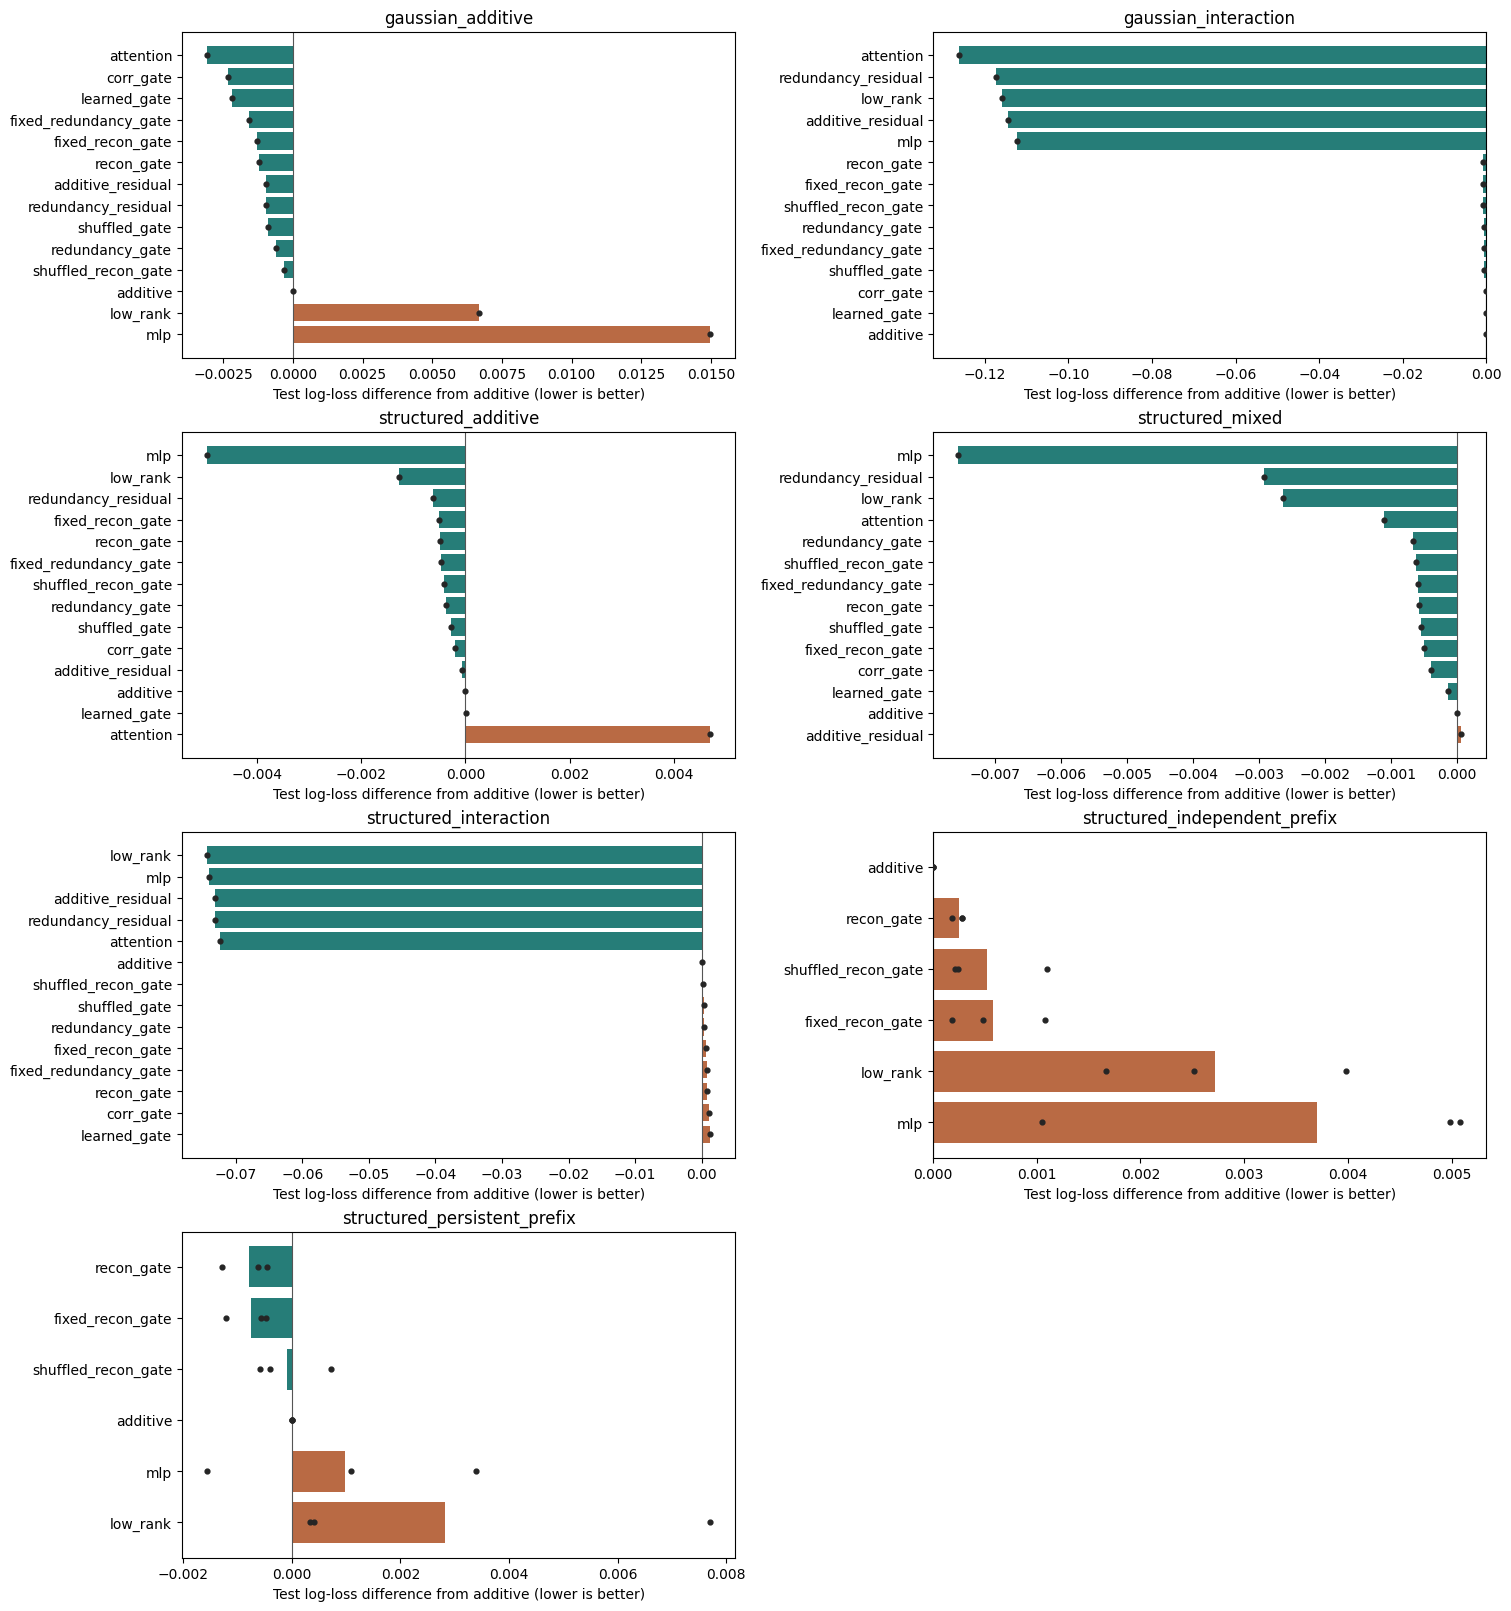

Epoch-cap trials (case, seed, model, learning rate, best epoch): [('structured_mixed', 42, 'redundancy_residual', 0.001, 278)]
Dots are individual seed differences; bars are their means, not confidence intervals.


In [6]:
display(Markdown(comparison_markdown(bundle)))
figure = plot_comparison(bundle)
plt.show()

capped = [(name, result["data_config"]["seed"], run["variant"], trial["learning_rate"], trial["best_epoch"])
          for name, results in bundle["cases"].items() for result in results
          for run in result["runs"] for trial in run["trials"]
          if len(trial["history"]) == result["training_config"]["epochs"]]
print("Epoch-cap trials (case, seed, model, learning rate, best epoch):", capped)
print("Dots are individual seed differences; bars are their means, not confidence intervals.")

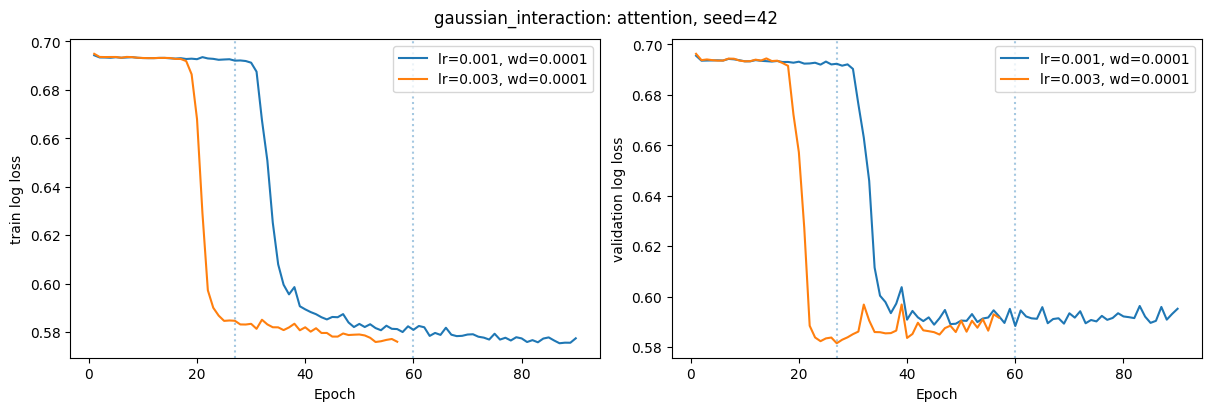

Export: /content/feature_dependence_model_structure_study/results/notebook/20261024T060825490964Z
Saved predictions, trial histories, selected settings, scaling, gate scores and CSV summaries.


In [7]:
HISTORY_CASE = "gaussian_interaction"
HISTORY_MODEL = "attention"
HISTORY_SEED_INDEX = 0

figure = plot_history(bundle, HISTORY_CASE, HISTORY_MODEL, HISTORY_SEED_INDEX)
plt.show()

output_root = study_root / "results" / ("smoke" if SMOKE else "notebook")
output = export_results(bundle, output_root)
print("Export:", output)
print("Saved predictions, trial histories, selected settings, scaling, gate scores and CSV summaries.")

## Interpretation

The checked full-size results and case-specific conclusions are in [ANALYSIS.md](ANALYSIS.md). Explicit interaction targets show a large advantage for interaction-capable models over static additive variants. Rankings among flexible models vary by feature law and target. The persistent-prefix reconstructability gate's mean edge is small, and the fixed-gate control is nearly tied with it.

These are selected illustrative cases, not an independent confirmatory benchmark. Core cases have one seed, prefix cases three; seed changes affect observations and initialization together. Positive static gates preserve the additive function class and cannot supply cross-feature interactions. Paired shuffled and fixed controls are necessary before attributing a small gain to informative scores or learned correction. Prefix tests span source periods and do not establish future-only forecasting performance. Smoke output supports execution checks only.